# Training MLP 4 lớp — so sánh 3 phương pháp DSP

Notebook tối giản cho bài toán **Normal / IR / OR / B**, dùng **28 đặc trưng**, chia tập **Stratified Group K-Fold** theo `file_id`, huấn luyện MLP với số epoch cố định và đánh giá theo **file**.

Ba phương pháp so sánh: `hybrid`, `square_law`, `hilbert_offline`. `hilbert_offline` là tham chiếu dùng phép Hilbert theo khối, không phải triển khai thời gian thực trên MCU.

Notebook không dùng cache, SNR sweep, bootstrap CI hoặc lưu kết quả trung gian. Mean và variance của Z-score chỉ được fit trên Train của từng fold.

In [ ]:
# CELL 2 — Môi trường & imports
import os, sys
sys.path.insert(0, os.path.abspath('../../'))

import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

from common import config as cfg, dsp, features_full, models, io_utils

In [ ]:
# CELL 3 — Cấu hình
FEATURES_DIR = os.path.abspath('../giai_doan_1_tien_xu_ly/outputs/tables')
FEATURE_FILES = {
    'hybrid': 'features_mlp_hybrid',
    'square_law': 'features_mlp_square_law',
    'hilbert_offline': 'features_mlp_hilbert',
}
METHODS = ['hybrid', 'square_law', 'hilbert_offline']

CLASS_NAMES = cfg.CLASSES_4
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
LABEL_COL, GROUP_COL = 'label', 'file_id'

TARGET_FS_HZ = cfg.SCOPE['sampling_rate_hz']
BAND_HZ = cfg.RESONANCE_BAND_HZ
LP_CUTOFF_HZ = cfg.LP_CUTOFF_HZ
BANDPASS_ORDER = dsp.BENCHMARK_BANDPASS_ORDER
LOWPASS_ORDER = dsp.BENCHMARK_LOWPASS_ORDER
WINDOW_SIZE = cfg.WINDOW_SIZE_RAW
STRIDE = cfg.STRIDE_RAW
WARMUP_SAMPLES = cfg.WARMUP_SAMPLES

K = 4
SEEDS = list(range(42, 52))
EPOCHS = 40
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
SNR_LEVELS_DB = [-4, 0, 4, 8]
ABLATION_SEEDS = SEEDS[:3]  # ablation gọn hơn; kết quả mang tính phân tích
EXPORT_DIR = os.path.abspath('../../outputs/model_export')

print(f'Features: {FEATURES_DIR}')
print(f'Classes: {CLASS_NAMES}; K={K}; seeds={SEEDS[0]}–{SEEDS[-1]}')

Features: f:\CODE\NCKH_TinyML\TinyML_CWRU\notebooks\giai_doan_1_tien_xu_ly\outputs\tables
Classes: ['Normal', 'IR', 'OR', 'B']; K=4; seeds=42–51


## 1. Đọc manifest và tạo fold dùng chung

`manifest.csv` cần là manifest đã được tạo từ dự án, có metadata sampling rate và RPM. Bộ lọc phạm vi dưới đây dùng lại quy tắc sẵn có trong `io_utils`; fold được dựng một lần cho mỗi seed và tái sử dụng cho cả ba phương pháp.

In [ ]:
def load_feature_table(stem):
    csv_path = os.path.join(FEATURES_DIR, stem + '.csv')
    parquet_path = os.path.join(FEATURES_DIR, stem + '.parquet')
    if os.path.exists(csv_path):
        return pd.read_csv(csv_path)
    return pd.read_parquet(parquet_path)

feature_tables = {m: load_feature_table(FEATURE_FILES[m]) for m in METHODS}
feature_cols = {
    m: features_full.feature_columns(df, expected_count=28, strict_prefix=True)
    for m, df in feature_tables.items()
}

file_meta = (feature_tables['hybrid'][[GROUP_COL, LABEL_COL]]
             .drop_duplicates().reset_index(drop=True))
file_meta['label_id'] = file_meta[LABEL_COL].map(CLASS_TO_ID)

# Giữ cùng tập file và cùng thứ tự cột để so sánh DSP công bằng.
reference_files = set(file_meta[GROUP_COL].astype(str))
for method, df in feature_tables.items():
    if set(df[GROUP_COL].astype(str)) != reference_files:
        raise ValueError(f'{method}: tập file khác với bảng Hybrid.')
    if set(feature_cols[method]) != set(feature_cols['hybrid']):
        raise ValueError(f'{method}: bộ 28 đặc trưng khác với bảng Hybrid.')
    feature_tables[method][GROUP_COL] = feature_tables[method][GROUP_COL].astype(str)
    feature_tables[method][LABEL_COL] = feature_tables[method][LABEL_COL].astype(str)

file_meta[GROUP_COL] = file_meta[GROUP_COL].astype(str)
file_meta[LABEL_COL] = file_meta[LABEL_COL].astype(str)
file_meta['label_id'] = file_meta[LABEL_COL].map(CLASS_TO_ID)
display(file_meta.groupby(LABEL_COL)[GROUP_COL].nunique().rename('Số file').to_frame())

,Số file
label,
B,12
IR,12
Normal,4
OR,12


## 2. Tạo fold dùng chung

Mỗi file xuất hiện trong Test đúng một lần trong mỗi seed; không có cửa sổ của cùng file_id nằm đồng thời ở Train và Test.

In [ ]:
FOLDS = {}
for seed in SEEDS:
    cv = StratifiedGroupKFold(n_splits=K, shuffle=True, random_state=seed)
    splits = []
    for train_idx, test_idx in cv.split(
        np.zeros(len(file_meta)), file_meta['label_id'], file_meta[GROUP_COL]
    ):
        splits.append((
            set(file_meta.iloc[train_idx][GROUP_COL]),
            set(file_meta.iloc[test_idx][GROUP_COL]),
        ))
    FOLDS[seed] = splits


def file_level_rows(method, seed, fold_id, test_df, window_probabilities):
    """Gộp xác suất các cửa sổ của mỗi file thành một dự đoán."""
    rows = []
    for file_id, indices in test_df.groupby(GROUP_COL, sort=False).indices.items():
        mean_prob = window_probabilities[indices].mean(axis=0)
        row = {
            'method': method, 'seed': seed, 'fold': fold_id,
            'file_id': str(file_id),
            'y_true': str(test_df.iloc[indices[0]][LABEL_COL]),
            'y_pred': CLASS_NAMES[int(np.argmax(mean_prob))],
        }
        row.update({f'p_{i}': float(p) for i, p in enumerate(mean_prob)})
        rows.append(row)
    return rows

## 3. Huấn luyện

Trong từng fold: fit Z-score trên Train, khởi tạo và compile MLP mới, huấn luyện số epoch cố định; sau đó lấy trung bình xác suất các cửa sổ của cùng file để đưa ra đúng một dự đoán/file.

In [ ]:
file_prediction_rows = []
history_log = {m: [] for m in METHODS}
fold_weights, fold_scalers = {}, {}

for method in METHODS:
    print(f'\n===== {method} =====')
    df = feature_tables[method].reset_index(drop=True)
    cols = feature_cols[method]

    for seed, splits in FOLDS.items():
        for fold_id, (train_files, test_files) in enumerate(splits, start=1):
            train_df = df[df[GROUP_COL].isin(train_files)].reset_index(drop=True)
            test_df = df[df[GROUP_COL].isin(test_files)].reset_index(drop=True)

            scaler = StandardScaler()
            X_train = scaler.fit_transform(train_df[cols].to_numpy(dtype=np.float32))
            X_test = scaler.transform(test_df[cols].to_numpy(dtype=np.float32))
            y_train = train_df[LABEL_COL].map(CLASS_TO_ID).to_numpy(dtype=np.int32)

            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(seed * 100 + fold_id)
            model = models.build_primary_mlp(input_dim=len(cols), n_classes=len(CLASS_NAMES))
            models.compile_classifier(model, learning_rate=LEARNING_RATE, n_classes=len(CLASS_NAMES))
            history = model.fit(
                X_train, y_train, epochs=EPOCHS,
                batch_size=BATCH_SIZE, verbose=0,
            )

            history_log[method].append({
                key: np.asarray(values, dtype=float)
                for key, values in history.history.items()
            })
            key = (method, seed, fold_id)
            fold_scalers[key] = scaler

            probabilities = model.predict(X_test, verbose=0)
            file_prediction_rows.extend(
                file_level_rows(method, seed, fold_id, test_df, probabilities)
            )
            fold_weights[key] = [weight.copy() for weight in model.get_weights()]
            del model
            tf.keras.backend.clear_session()
        print(f'  seed {seed} hoàn tất')

predictions_df = pd.DataFrame(file_prediction_rows)
print(f'Hoàn thành {len(fold_weights)} mô hình; {len(predictions_df)} dự đoán mức file.')


===== hybrid =====

  seed 42 hoàn tất
  seed 43 hoàn tất
  seed 44 hoàn tất
  seed 45 hoàn tất
  seed 46 hoàn tất
  seed 47 hoàn tất
  seed 48 hoàn tất
  seed 49 hoàn tất
  seed 50 hoàn tất
  seed 51 hoàn tất

===== square_law =====
  seed 42 hoàn tất
  seed 43 hoàn tất
  seed 44 hoàn tất
  seed 45 hoàn tất
  seed 46 hoàn tất
  seed 47 hoàn tất
  seed 48 hoàn tất
  seed 49 hoàn tất
  seed 50 hoàn tất
  seed 51 hoàn tất

===== hilbert_offline =====
  seed 42 hoàn tất
  seed 43 hoàn tất
  seed 44 hoàn tất
  seed 45 hoàn tất
  seed 46 hoàn tất
  seed 47 hoàn tất
  seed 48 hoàn tất
  seed 49 hoàn tất
  seed 50 hoàn tất
  seed 51 hoàn tất
Hoàn thành 120 mô hình; 1200 dự đoán mức file.


## 4. Accuracy và Macro-F1 theo file

Mỗi seed được tính trên các dự đoán out-of-fold đã ghép qua đủ bốn fold. Bảng tổng hợp báo cáo mean ± std qua 10 seed; độ lệch chuẩn này chỉ mô tả biến thiên giữa các lần chạy, không được diễn giải như 10 tập Test độc lập.

In [ ]:
seed_results = []
for (method, seed), group in predictions_df.groupby(['method', 'seed'], sort=False):
    seed_results.append({
        'method': method,
        'seed': seed,
        'accuracy': accuracy_score(group['y_true'], group['y_pred']),
        'macro_f1': f1_score(
            group['y_true'], group['y_pred'], labels=CLASS_NAMES,
            average='macro', zero_division=0,
        ),
    })

metrics_by_seed = pd.DataFrame(seed_results)
summary = (metrics_by_seed.groupby('method')
           .agg(accuracy_mean=('accuracy', 'mean'), accuracy_std=('accuracy', 'std'),
                macro_f1_mean=('macro_f1', 'mean'), macro_f1_std=('macro_f1', 'std'))
           .reindex(METHODS).reset_index())
display(metrics_by_seed.pivot(index='seed', columns='method', values='accuracy').round(4))
display(metrics_by_seed.pivot(index='seed', columns='method', values='macro_f1').round(4))
display(summary.round(4))

method,hilbert_offline,hybrid,square_law
seed,,,
42,0.925,0.925,0.900
43,0.850,0.850,0.875
44,0.900,0.900,0.900
45,0.875,0.875,0.900
46,0.900,0.900,0.900
47,0.900,0.900,0.875
48,0.875,0.875,0.900
49,0.875,0.875,0.875
50,0.875,0.875,0.850


method,hilbert_offline,hybrid,square_law
seed,,,
42,0.9124,0.9124,0.8930
43,0.8359,0.8359,0.8544
44,0.8748,0.8748,0.8748
45,0.8432,0.8432,0.8748
46,0.8748,0.8748,0.8748
47,0.8748,0.8748,0.8544
48,0.8556,0.8556,0.8930
49,0.8556,0.8556,0.8432
50,0.8348,0.8348,0.8149


,method,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
0,hybrid,0.885,0.0211,0.8605,0.0241
1,square_law,0.885,0.0175,0.8620,0.0246
2,hilbert_offline,0.885,0.0211,0.8605,0.0241


# Learning curves
Đường cong là trung bình ± độ lệch chuẩn của các lần fit qua fold/seed cho từng phương pháp. Vì giao thức hiện không tách Validation, đây là training loss/accuracy, không nên diễn giải như đường cong tổng quát hóa hoặc bằng chứng độc lập về overfitting.

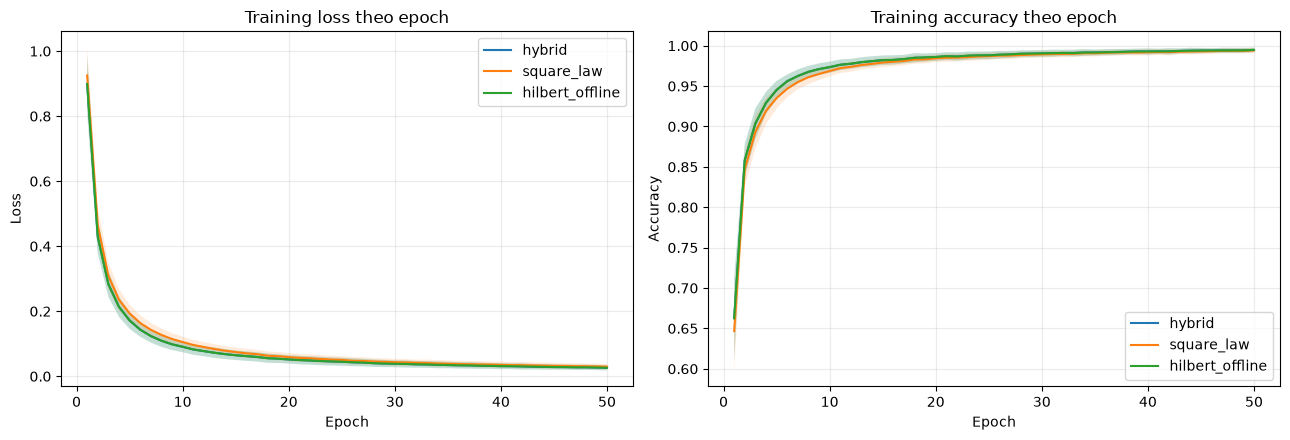

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
epoch_axis = np.arange(1, EPOCHS + 1)
for method in METHODS:
    loss_curves = np.stack([h['loss'] for h in history_log[method]])
    acc_curves = np.stack([h['accuracy'] for h in history_log[method]])

    loss_mean, loss_std = loss_curves.mean(axis=0), loss_curves.std(axis=0)
    acc_mean, acc_std = acc_curves.mean(axis=0), acc_curves.std(axis=0)

    axes[0].plot(epoch_axis, loss_mean, label=method)
    axes[0].fill_between(epoch_axis, loss_mean-loss_std, loss_mean+loss_std, alpha=0.15)
    axes[1].plot(epoch_axis, acc_mean, label=method)
    axes[1].fill_between(epoch_axis, acc_mean-acc_std, acc_mean+acc_std, alpha=0.15)

axes[0].set(title='Training loss theo epoch', xlabel='Epoch', ylabel='Loss')
axes[1].set(title='Training accuracy theo epoch', xlabel='Epoch', ylabel='Accuracy')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

# Confusion matrix theo file
Để không đếm một file mười lần trong hình, xác suất OOF của file được lấy trung bình qua 10 seed rồi mới tính confusion matrix. Đây là hình tóm tắt theo file; bảng mean ± std ở mục trước vẫn là kết quả CV chính.

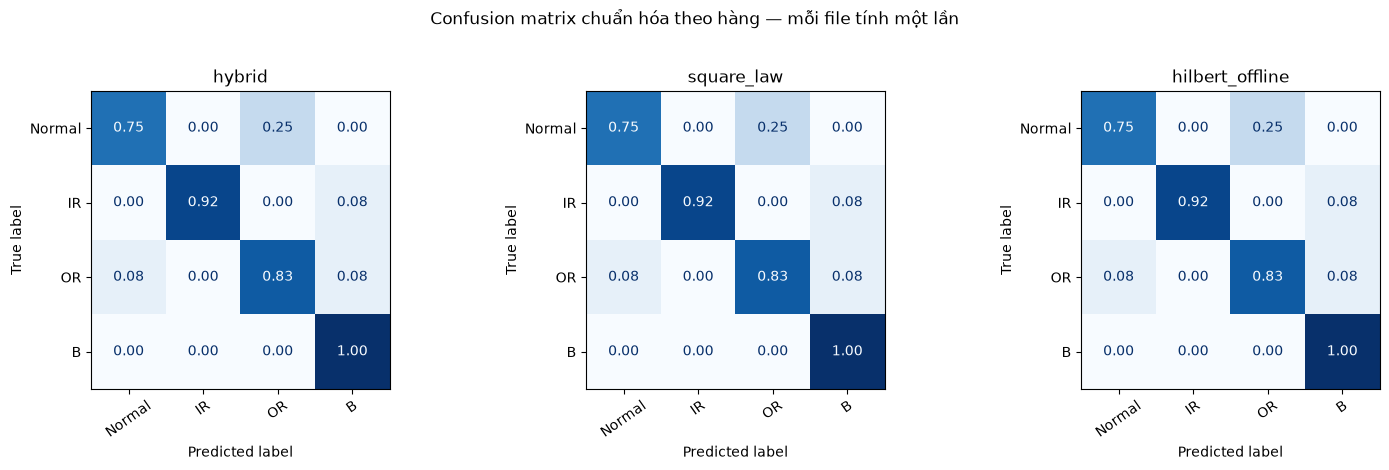

In [ ]:
prob_cols = [f'p_{i}' for i in range(len(CLASS_NAMES))]
fig, axes = plt.subplots(1, len(METHODS), figsize=(5 * len(METHODS), 4.5))

for ax, method in zip(axes, METHODS):
    part = predictions_df[predictions_df['method'] == method]
    aggregation = {col: 'mean' for col in prob_cols}
    aggregation['y_true'] = 'first'
    one_row_per_file = part.groupby('file_id', as_index=False).agg(aggregation)
    y_true = one_row_per_file['y_true'].to_numpy()
    y_pred = np.asarray(CLASS_NAMES)[one_row_per_file[prob_cols].to_numpy().argmax(axis=1)]
    cm = confusion_matrix(y_true, y_pred, labels=CLASS_NAMES, normalize='true')
    disp = ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES)
    disp.plot(ax=ax, values_format='.2f', colorbar=False, cmap='Blues')
    ax.set_title(method)
    ax.tick_params(axis='x', rotation=35)

plt.suptitle('Confusion matrix chuẩn hóa theo hàng — mỗi file tính một lần', y=1.03)
plt.tight_layout()
plt.show()

# 7. Robustness to noise — AWGN trên tín hiệu thô trước DSP
Khác với việc cộng nhiễu trực tiếp vào 28 đặc trưng, phép thử này cộng AWGN vào tín hiệu rung sau khi resample về 12 kHz nhưng trước BPF/envelope, rồi trích lại đặc trưng cho mỗi phương pháp. Nó cần manifest giai đoạn 1 có `file_path`, `resolved_sample_rate_hz`, `resolved_sample_rate_source`, `rpm, rpm_source`.

In [ ]:
# Tìm manifest giai đoạn 1 chỉ để tải tín hiệu thô cho thí nghiệm nhiễu.
manifest_candidates = [
    os.path.join(FEATURES_DIR, 'manifest_filtered.csv'),
    os.path.join(FEATURES_DIR, 'manifest.csv'),
]
manifest_path = next((p for p in manifest_candidates if os.path.isfile(p)), None)
RAW_MANIFEST = None

if manifest_path is None:
    print('Không tìm thấy manifest_filtered.csv/manifest.csv; sẽ bỏ qua noise experiment. '
          'Các phân tích learning curve, confusion matrix, ablation và export vẫn có thể chạy.')
else:
    raw_manifest = pd.read_csv(manifest_path)
    required = ['file_path', 'label', 'resolved_sample_rate_hz',
                'resolved_sample_rate_source', 'rpm', 'rpm_source']
    missing = [c for c in required if c not in raw_manifest.columns]
    if missing:
        print(f'Manifest thiếu {missing}; bỏ qua noise experiment.')
    else:
        def file_stem(value):
            normalized = str(value).replace('\\', '/')
            return os.path.splitext(normalized.rsplit('/', 1)[-1])[0]

        project_root = os.path.abspath('../../')
        stage1_dir = os.path.abspath('../giai_doan_1_tien_xu_ly')

        def resolve_raw_path(value):
            raw = os.path.expandvars(os.path.expanduser(str(value)))
            candidates = [raw] if os.path.isabs(raw) else [
                os.path.abspath(os.path.join(stage1_dir, raw)),
                os.path.abspath(os.path.join(project_root, raw)),
                os.path.abspath(raw),
            ]
            for candidate in candidates:
                if os.path.isfile(candidate):
                    return os.path.abspath(candidate)
            return candidates[0]

        raw_manifest['file_id'] = raw_manifest['file_path'].map(file_stem)
        feature_file_ids = set(feature_tables['hybrid'][GROUP_COL].astype(str))
        raw_manifest = raw_manifest[
            raw_manifest['file_id'].isin(feature_file_ids)
            & raw_manifest['label'].astype(str).isin(CLASS_NAMES)
        ].copy()
        raw_manifest['file_path'] = raw_manifest['file_path'].map(resolve_raw_path)
        missing_paths = raw_manifest.loc[~raw_manifest['file_path'].map(os.path.isfile), 'file_path']
        missing_ids = reference_files - set(raw_manifest['file_id'].astype(str))

        if len(raw_manifest) and len(missing_paths) == 0 and not missing_ids:
            RAW_MANIFEST = raw_manifest.drop(columns=['file_id']).reset_index(drop=True)
            print(f'Manifest nhiễu: {manifest_path}; {len(RAW_MANIFEST)} file raw đã ghép được.')
        else:
            print(f'Không ghép đủ dữ liệu raw: {len(missing_paths)} đường dẫn thiếu, '
                  f'{len(missing_ids)} file chưa có trong manifest; bỏ qua noise experiment.')

Manifest nhiễu: f:\CODE\NCKH_TinyML\TinyML_CWRU\notebooks\giai_doan_1_tien_xu_ly\outputs\tables\manifest_filtered.csv; 40 file raw đã ghép được.


# 7.1. Hàm AWGN và trích đặc trưng nhiễu
Nhiễu có seed ổn định theo (SNR, file_id), nên cùng một tín hiệu nhiễu được tái sử dụng cho cả ba phương pháp `DSP. Square-law` được dispatch cục bộ trong notebook vì một số phiên bản `dsp.envelope_by_method` chưa có nhánh `square_law`.

In [ ]:
def add_awgn(signal, snr_db, seed):
    signal = np.asarray(signal, dtype=np.float64)
    # Ước lượng công suất AC để DC offset không chi phối SNR.
    centered = signal - np.mean(signal)
    signal_power = np.mean(centered ** 2)
    rng = np.random.default_rng(seed)
    noise = rng.standard_normal(signal.shape)
    noise_power = np.mean(noise ** 2)
    if signal_power <= 0 or noise_power <= 0:
        return signal.copy()
    target_noise_power = signal_power / (10.0 ** (snr_db / 10.0))
    noise *= np.sqrt(target_noise_power / noise_power)
    return signal + noise


def make_awgn_loader(snr_db):
    def loader(filepath, source_fs_hz, target_fs_hz):
        x = io_utils.load_de_signal_resampled(filepath, source_fs_hz, target_fs_hz)
        seed_text = f'CWRU-AWGN-v1|{snr_db}|{file_stem(filepath)}'
        seed = int(hashlib.sha256(seed_text.encode('utf-8')).hexdigest()[:8], 16)
        return add_awgn(x, snr_db, seed)
    return loader


def dispatch_with_square_law(x, fs, band=None, method='hybrid', **kwargs):
    name = str(method).lower().replace('-', '_')
    if name == 'square_law':
        return dsp.square_law_envelope(x, fs, band=band, **kwargs)
    return ORIGINAL_ENVELOPE_DISPATCH(x, fs, band=band, method=name, **kwargs)


noise_feature_tables = {}
noise_predictions_df = pd.DataFrame()
noise_summary = pd.DataFrame()

if RAW_MANIFEST is not None:
    ORIGINAL_ENVELOPE_DISPATCH = dsp.envelope_by_method
    try:
        dsp.envelope_by_method = dispatch_with_square_law
        for snr_db in SNR_LEVELS_DB:
            for method in METHODS:
                print(f'Trích đặc trưng noisy: {method}, SNR={snr_db} dB')
                noise_feature_tables[(method, snr_db)] = features_full.build_full_feature_table(
                    RAW_MANIFEST,
                    band_hz=BAND_HZ,
                    load_de_signal_fn=make_awgn_loader(snr_db),
                    window_size=WINDOW_SIZE,
                    stride=STRIDE,
                    warmup_samples=WARMUP_SAMPLES,
                    target_fs_hz=TARGET_FS_HZ,
                    lp_cutoff_hz=LP_CUTOFF_HZ,
                    bandpass_order=BANDPASS_ORDER,
                    lowpass_order=LOWPASS_ORDER,
                    envelope_method=method,
                )
    finally:
        dsp.envelope_by_method = ORIGINAL_ENVELOPE_DISPATCH

Trích đặc trưng noisy: hybrid, SNR=-4 dB
Trích đặc trưng noisy: square_law, SNR=-4 dB
Trích đặc trưng noisy: hilbert_offline, SNR=-4 dB
Trích đặc trưng noisy: hybrid, SNR=0 dB
Trích đặc trưng noisy: square_law, SNR=0 dB
Trích đặc trưng noisy: hilbert_offline, SNR=0 dB
Trích đặc trưng noisy: hybrid, SNR=4 dB
Trích đặc trưng noisy: square_law, SNR=4 dB
Trích đặc trưng noisy: hilbert_offline, SNR=4 dB
Trích đặc trưng noisy: hybrid, SNR=8 dB
Trích đặc trưng noisy: square_law, SNR=8 dB
Trích đặc trưng noisy: hilbert_offline, SNR=8 dB


# Đánh giá Test nhiễu bằng model/scaler của đúng fold
Train không bị nhiễu và không được fit lại. Mỗi noisy Test dùng scaler và model tương ứng của cùng (`method, seed, fold`); chỉ các file thuộc Test fold được chấm điểm.

,method,snr_db,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
0,hilbert_offline,-4,0.2900,0.0860,0.2314,0.0967
1,hilbert_offline,0,0.3125,0.0899,0.2661,0.1137
2,hilbert_offline,4,0.4425,0.0906,0.4243,0.0992
3,hilbert_offline,8,0.7225,0.0546,0.7119,0.0527
4,hybrid,-4,0.3025,0.0845,0.2404,0.0914
5,hybrid,0,0.3125,0.0937,0.2668,0.1118
6,hybrid,4,0.4425,0.0800,0.4191,0.0905
7,hybrid,8,0.7100,0.0648,0.7000,0.0618
8,square_law,-4,0.2825,0.0501,0.2213,0.0716
9,square_law,0,0.3275,0.0629,0.2710,0.0858


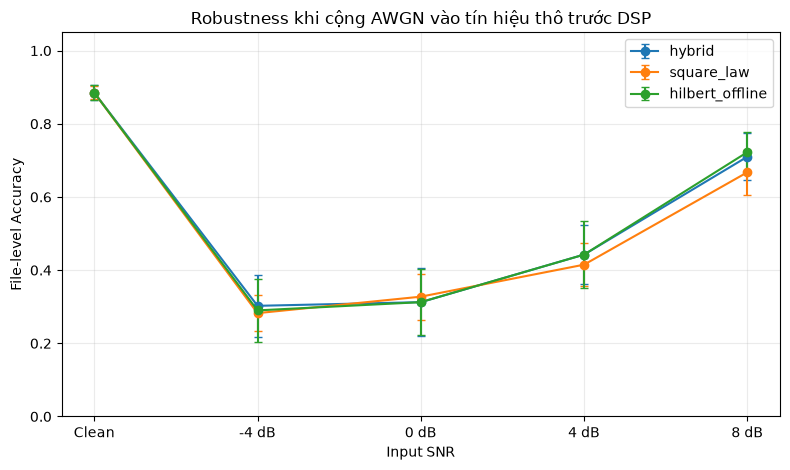

In [ ]:
if noise_feature_tables:
    noise_rows = []
    for method in METHODS:
        cols = feature_cols[method]
        for seed, splits in FOLDS.items():
            for fold_id, (train_files, test_files) in enumerate(splits, start=1):
                key = (method, seed, fold_id)
                tf.keras.backend.clear_session()
                eval_model = models.build_primary_mlp(
                    input_dim=len(cols), n_classes=len(CLASS_NAMES)
                )
                eval_model.set_weights(fold_weights[key])
                scaler = fold_scalers[key]

                for snr_db in SNR_LEVELS_DB:
                    noisy_df = noise_feature_tables[(method, snr_db)].copy()
                    noisy_df[GROUP_COL] = noisy_df[GROUP_COL].astype(str)
                    noisy_df[LABEL_COL] = noisy_df[LABEL_COL].astype(str)
                    test_df = noisy_df[noisy_df[GROUP_COL].isin(test_files)].reset_index(drop=True)
                    X_noisy = scaler.transform(test_df[cols].to_numpy(dtype=np.float32))
                    probs = eval_model.predict(X_noisy, verbose=0)
                    rows = file_level_rows(method, seed, fold_id, test_df, probs)
                    for row in rows:
                        row['snr_db'] = snr_db
                    noise_rows.extend(rows)

                del eval_model
                tf.keras.backend.clear_session()

    noise_predictions_df = pd.DataFrame(noise_rows)
    noise_seed_metrics = []
    for (method, snr_db, seed), group in noise_predictions_df.groupby(
        ['method', 'snr_db', 'seed'], sort=False
    ):
        noise_seed_metrics.append({
            'method': method, 'snr_db': snr_db, 'seed': seed,
            'accuracy': accuracy_score(group['y_true'], group['y_pred']),
            'macro_f1': f1_score(group['y_true'], group['y_pred'], labels=CLASS_NAMES,
                                 average='macro', zero_division=0),
        })
    noise_seed_metrics = pd.DataFrame(noise_seed_metrics)
    noise_summary = (noise_seed_metrics.groupby(['method', 'snr_db'])
                     .agg(accuracy_mean=('accuracy', 'mean'), accuracy_std=('accuracy', 'std'),
                          macro_f1_mean=('macro_f1', 'mean'), macro_f1_std=('macro_f1', 'std'))
                     .reset_index())
    display(noise_summary.round(4))

    # Thêm điểm Clean từ CV gốc; error bars là SD qua seed.
    clean_points = metrics_by_seed.groupby('method')['accuracy'].agg(['mean', 'std'])
    x_labels = ['Clean'] + [f'{s} dB' for s in SNR_LEVELS_DB]
    x = np.arange(len(x_labels))
    plt.figure(figsize=(8, 4.8))
    for method in METHODS:
        means = [clean_points.loc[method, 'mean']]
        stds = [clean_points.loc[method, 'std']]
        for snr_db in SNR_LEVELS_DB:
            row = noise_summary[(noise_summary.method == method) & (noise_summary.snr_db == snr_db)].iloc[0]
            means.append(row['accuracy_mean'])
            stds.append(row['accuracy_std'])
        plt.errorbar(x, means, yerr=stds, marker='o', capsize=3, label=method)
    plt.xticks(x, x_labels)
    plt.ylim(0, 1.05)
    plt.ylabel('File-level Accuracy')
    plt.xlabel('Input SNR')
    plt.title('Robustness khi cộng AWGN vào tín hiệu thô trước DSP')
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Noise analysis đã bỏ qua vì manifest/tệp raw chưa sẵn sàng.')

# 8. Ablation study: bỏ từng nhóm đặc trưng
Chọn phương pháp DSP có Macro-F1 CV trung bình cao nhất. Sau đó chạy `leave-one-group-out` với 3 seed đầu đã định trước (`42–44`) để giữ chi phí hợp lý: lần lượt bỏ toàn bộ `time_, order_ hoặc envelope_.` Kết quả ablation là phân tích mô tả; nếu chọn phương pháp từ cùng CV rồi phân tích tiếp trên các fold đó, không nên xem đây là xác nhận độc lập.

In [ ]:
# Chọn Hybrid làm method ablation để phân tích nhóm đặc trưng.
method_ablation = "hybrid"
best_df = feature_tables[method_ablation].reset_index(drop=True)
best_cols = feature_cols[method_ablation]
feature_groups = {
    'Time-domain': [c for c in best_cols if c.startswith('time_')],
    'Order/frequency': [c for c in best_cols if c.startswith('order_')],
    'Envelope': [c for c in best_cols if c.startswith('envelope_')],
}

# Base line: kết quả full-feature đã có, lấy cùng các seed 42–44.
base_rows = predictions_df[
    (predictions_df['method'] == method_ablation)
    & predictions_df['seed'].isin(ABLATION_SEEDS)
].copy()
base_rows['variant'] = 'All 28 features'
ablation_prediction_rows = base_rows.to_dict('records')

for group_name, remove_cols in feature_groups.items():
    cols = [c for c in best_cols if c not in remove_cols]
    variant = f'Without {group_name}'
    print(f'Ablation {variant}: {len(cols)} features')

    for seed in ABLATION_SEEDS:
        for fold_id, (train_files, test_files) in enumerate(FOLDS[seed], start=1):
            train_df = best_df[best_df[GROUP_COL].isin(train_files)].reset_index(drop=True)
            test_df = best_df[best_df[GROUP_COL].isin(test_files)].reset_index(drop=True)
            scaler = StandardScaler()
            X_train = scaler.fit_transform(train_df[cols].to_numpy(dtype=np.float32))
            X_test = scaler.transform(test_df[cols].to_numpy(dtype=np.float32))
            y_train = train_df[LABEL_COL].map(CLASS_TO_ID).to_numpy(dtype=np.int32)

            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(seed * 100 + fold_id)
            ablation_model = models.build_primary_mlp(input_dim=len(cols), n_classes=len(CLASS_NAMES))
            models.compile_classifier(ablation_model, learning_rate=LEARNING_RATE,
                                      n_classes=len(CLASS_NAMES))
            ablation_model.fit(X_train, y_train, epochs=EPOCHS,
                               batch_size=BATCH_SIZE, verbose=0)
            probs = ablation_model.predict(X_test, verbose=0)
            new_rows = file_level_rows(variant, seed, fold_id, test_df, probs)
            for row in new_rows:
                row['variant'] = variant
            ablation_prediction_rows.extend(new_rows)
            del ablation_model
            tf.keras.backend.clear_session()

ablation_predictions_df = pd.DataFrame(ablation_prediction_rows)
ablation_seed_metrics = []
for (variant, seed), group in ablation_predictions_df.groupby(['variant', 'seed'], sort=False):
    ablation_seed_metrics.append({
        'variant': variant, 'seed': seed,
        'accuracy': accuracy_score(group['y_true'], group['y_pred']),
        'macro_f1': f1_score(group['y_true'], group['y_pred'], labels=CLASS_NAMES,
                             average='macro', zero_division=0),
    })
ablation_seed_metrics = pd.DataFrame(ablation_seed_metrics)
ablation_summary = (ablation_seed_metrics.groupby('variant')
                    .agg(accuracy_mean=('accuracy', 'mean'), accuracy_std=('accuracy', 'std'),
                         macro_f1_mean=('macro_f1', 'mean'), macro_f1_std=('macro_f1', 'std'))
                    .reset_index())
base = ablation_summary.loc[ablation_summary.variant == 'All 28 features'].iloc[0]
ablation_summary['accuracy_drop_pp'] = (base['accuracy_mean'] - ablation_summary['accuracy_mean']) * 100
ablation_summary['macro_f1_drop_pp'] = (base['macro_f1_mean'] - ablation_summary['macro_f1_mean']) * 100
display(ablation_summary.round(4))

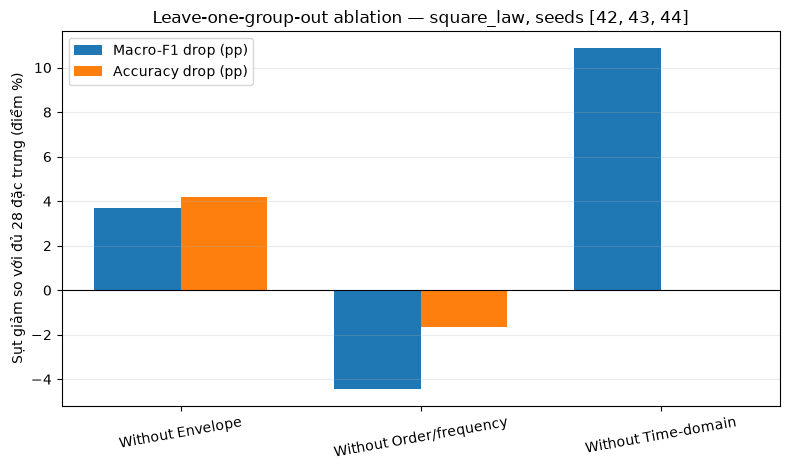

In [ ]:
plot_df = ablation_summary[ablation_summary['variant'] != 'All 28 features'].copy()
x = np.arange(len(plot_df))
width = 0.36
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(x - width/2, plot_df['macro_f1_drop_pp'], width, label='Macro-F1 drop (pp)')
ax.bar(x + width/2, plot_df['accuracy_drop_pp'], width, label='Accuracy drop (pp)')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x, plot_df['variant'], rotation=10)
ax.set_ylabel('Sụt giảm so với đủ 28 đặc trưng (điểm %)')
ax.set_title(f'Leave-one-group-out ablation — {method_ablation}, seeds {ABLATION_SEEDS}')
ax.legend()
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

# Xuất MLP cho STM32Cube.AI

In [ ]:
os.makedirs(EXPORT_DIR, exist_ok=True)
export_results = {}

def export_method(method):
    df = feature_tables[method].reset_index(drop=True)
    cols = feature_cols[method]
    X = df[cols].to_numpy(dtype=np.float32)
    y = df[LABEL_COL].map(CLASS_TO_ID).to_numpy(dtype=np.int32)

    norm_mean = X.mean(axis=0).astype(np.float32)
    raw_var = X.var(axis=0)
    norm_var = np.where(raw_var < 1e-12, 1.0, raw_var).astype(np.float32)

    tf.keras.utils.set_random_seed(42)
    full_model = models.build_primary_mlp(
        input_dim=len(cols), n_classes=len(CLASS_NAMES),
        norm_mean=norm_mean, norm_variance=norm_var,
        name=f'mlp_4class_{method}_deploy',
    )
    full_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                        loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    full_model.fit(X, y, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0)

    deploy_model = models.build_primary_mlp(
        input_dim=len(cols), n_classes=len(CLASS_NAMES),
        name=f'mlp_4class_{method}_deployment_fused',
    )
    first_kernel, first_bias = full_model.get_layer('dense_32_0').get_weights()
    feature_scale = np.sqrt(norm_var)
    fused_kernel = first_kernel / feature_scale[:, None]
    fused_bias = first_bias - (norm_mean / feature_scale) @ first_kernel
    deploy_model.get_layer('dense_32_0').set_weights([fused_kernel, fused_bias])
    for layer_name in ['dense_16_1', 'output']:
        deploy_model.get_layer(layer_name).set_weights(full_model.get_layer(layer_name).get_weights())
    deploy_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                          loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    compare_n = min(256, len(X))
    fusion_err = float(np.max(np.abs(
        full_model.predict(X[:compare_n], verbose=0) - deploy_model.predict(X[:compare_n], verbose=0)
    )))

    h5_path = os.path.join(EXPORT_DIR, f'mlp_4class_{method}.h5')
    tflite_path = os.path.join(EXPORT_DIR, f'mlp_4class_{method}_int8.tflite')
    deploy_model.save(h5_path, include_optimizer=False)

    rng = np.random.default_rng(42)
    rep_idx = rng.choice(len(X), size=min(200, len(X)), replace=False)
    rep_samples = X[rep_idx]
    def representative_dataset():
        for sample in rep_samples:
            yield [sample.reshape(1, -1).astype(np.float32)]

    converter = tf.lite.TFLiteConverter.from_keras_model(deploy_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_dataset
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    tflite_bytes = converter.convert()
    with open(tflite_path, 'wb') as f:
        f.write(tflite_bytes)

    interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()
    in_detail = interpreter.get_input_details()[0]
    out_detail = interpreter.get_output_details()[0]
    in_scale, in_zero = in_detail['quantization']
    out_scale, out_zero = out_detail['quantization']

    parity_n = min(256, len(X))
    keras_pred = np.argmax(deploy_model.predict(X[:parity_n], verbose=0), axis=1)
    tflite_pred = []
    for sample in X[:parity_n]:
        q = np.clip(np.rint(sample / in_scale + in_zero), -128, 127).astype(np.int8)
        interpreter.set_tensor(in_detail['index'], q.reshape(1, -1))
        interpreter.invoke()
        out_q = interpreter.get_tensor(out_detail['index']).astype(np.float32)
        out_f = (out_q - out_zero) * out_scale
        tflite_pred.append(int(np.argmax(out_f[0])))
    agreement = float(np.mean(keras_pred == np.asarray(tflite_pred)))

    info = {
        'method': method,
        'cv_summary': summary[summary.method == method].iloc[0].to_dict(),
        'class_names_and_output_order': CLASS_NAMES,
        'keras_vs_tflite_top1_agreement': agreement,
        'feature_columns_in_input_order': cols,
        'input_shape': [1, len(cols)],
        'normalization_fusion_max_abs_probability_error': fusion_err,
        'keras_h5_path': os.path.abspath(h5_path),
        'tflite_int8_path': os.path.abspath(tflite_path),
        'tflite_input': {'dtype': str(in_detail['dtype']), 'shape': in_detail['shape'].tolist(),
                          'scale': float(in_scale), 'zero_point': int(in_zero)},
        'tflite_output': {'dtype': str(out_detail['dtype']), 'shape': out_detail['shape'].tolist(),
                           'scale': float(out_scale), 'zero_point': int(out_zero)},
    }
    print(f'[{method}] H5={h5_path}  TFLite={tflite_path}  TFLite-agreement={agreement:.3f}  fusion_err={fusion_err:.2e}')
    return info

for method in METHODS:
    export_results[method] = export_method(method)

with open(os.path.join(EXPORT_DIR, 'deployment_metadata_all_methods.json'), 'w', encoding='utf-8') as f:
    json.dump(export_results, f, ensure_ascii=False, indent=2,
              default=lambda x: float(x) if isinstance(x, (np.floating,)) else int(x) if isinstance(x, (np.integer,)) else str(x))
print('Đã xuất', len(export_results), 'bộ (H5 + TFLite INT8) cho', METHODS)

INFO:tensorflow:Assets written to: C:\Users\Admin\AppData\Local\Temp\tmpfent3enp\assets


INFO:tensorflow:Assets written to: C:\Users\Admin\AppData\Local\Temp\tmpfent3enp\assets


Saved artifact at 'C:\Users\Admin\AppData\Local\Temp\tmpfent3enp'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28), dtype=tf.float32, name='features')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  1627356361936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1627356361360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1627356352912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1627356359632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1627356359824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1627356361552: TensorSpec(shape=(), dtype=tf.resource, name=None)


f:\CODE\NCKH_TinyML\TinyML_CWRU\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
f:\CODE\NCKH_TinyML\TinyML_CWRU\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


[hybrid] H5=f:\CODE\NCKH_TinyML\TinyML_CWRU\outputs\model_export\mlp_4class_hybrid.h5  TFLite=f:\CODE\NCKH_TinyML\TinyML_CWRU\outputs\model_export\mlp_4class_hybrid_int8.tflite  TFLite-agreement=1.000  fusion_err=4.77e-07


...

INFO:tensorflow:Assets written to: C:\Users\Admin\AppData\Local\Temp\tmp8lx2g_x3\assets


Saved artifact at 'C:\Users\Admin\AppData\Local\Temp\tmp8lx2g_x3'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28), dtype=tf.float32, name='features')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  1627352595344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1627352583632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1627352585360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1627352589008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1627352594768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1627352586704: TensorSpec(shape=(), dtype=tf.resource, name=None)


f:\CODE\NCKH_TinyML\TinyML_CWRU\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


[hilbert_offline] H5=f:\CODE\NCKH_TinyML\TinyML_CWRU\outputs\model_export\mlp_4class_hilbert_offline.h5  TFLite=f:\CODE\NCKH_TinyML\TinyML_CWRU\outputs\model_export\mlp_4class_hilbert_offline_int8.tflite  TFLite-agreement=0.996  fusion_err=6.56e-07
Đã xuất 3 bộ (H5 + TFLite INT8) cho ['hybrid', 'square_law', 'hilbert_offline']


f:\CODE\NCKH_TinyML\TinyML_CWRU\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
